# K-means
- 无监督聚类
- 每个簇用一个 __质心(centroid)__ 代表,也就是簇内所有点的均值。
- 每个点到其所属质心的距离平方和,也叫 ___`簇内误差平方和(SSE / inertia)`___ ，即`K-means`的损失函数
- $J = \sum_{k=1}^{K}\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$
- 对该损失函数求导，很容易得到梯度——即 ___样本均值___

In [47]:
import torch

measurements = torch.tensor([
    [48.0, 1.2], [54.0, 2.6], [61.0, 1.5],
    [51.0, 3.4], [64.0, 2.9], [57.0, 2.1],
    [68.0, 1.8], [72.0, 1.3], [79.0, 2.0],
    [85.0, 3.1], [75.0, 3.6], [89.0, 1.7],
    [81.0, 4.2], [70.0, 2.7], [84.0, 2.5],
    [49.0, 5.0], [55.0, 6.4], [63.0, 5.6],
    [68.0, 4.5], [59.0, 4.1], [73.0, 5.8],
    [52.0, 4.2], [64.0, 6.7], [77.0, 4.9],
])
# 温差 10 °C 和振动差 1 mm/s 各对应一个距离单位。
feature_scale = torch.tensor([10.0, 1.0])
inputs = measurements / feature_scale
# 选择索引 1、3、5，让三个初始质心都从图的左侧出发。
initial_indices = [1, 3, 5]
centers = inputs[initial_indices].clone()
k_clusters = len(initial_indices)

In [48]:
def squared_distances(points, centers):
    # 准备一张距离表：每行对应一个样本，每列对应一个质心。
    distances = torch.zeros(len(points), len(centers))

    # 依次计算每个样本到每个质心的平方距离。
    for point_index, point in enumerate(points):
        for center_index, center in enumerate(centers):
            x_difference = point[0] - center[0]
            y_difference = point[1] - center[1]
            distances[point_index, center_index] = (
                x_difference ** 2 + y_difference ** 2
            )

    return distances

def calculate_loss(points, centers):
    # J 是每个样本到最近质心的平方距离之和。
    nearest = squared_distances(points, centers).min(dim=1).values
    return nearest.sum().item()

In [49]:
# 绘制每轮质心的位置，以及损失随迭代次数的变化。
import matplotlib.pyplot as plt

def plot_iteration(round_number):
    current = centers_history[round_number]
    assignments = squared_distances(inputs, current).argmin(dim=1)
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    colors = plt.get_cmap("tab10")
    for cluster in range(k_clusters):
        points = inputs[assignments == cluster]
        ax.scatter(points[:, 0], points[:, 1], color=colors(cluster), s=55, label=f"cluster {cluster}")
        path = torch.stack(centers_history[:round_number + 1])[:, cluster]
        ax.plot(path[:, 0], path[:, 1], "--o", color=colors(cluster), markersize=3)
        ax.scatter(*current[cluster], marker="X", s=160, color=colors(cluster), edgecolors="black")
    loss = calculate_loss(inputs, current)
    ax.set(xlabel="temperature / 10", ylabel="vibration (mm/s)", title=f"Round {round_number}, J={loss:.3f}")
    ax.set_xlim(4.5, 9.5)
    ax.set_ylim(0.5, 7.2)
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

def plot_loss():
    losses = [
        calculate_loss(inputs, saved_centers)
        for saved_centers in centers_history
    ]
    fig, ax = plt.subplots(figsize=(6.4, 3.2))
    ax.plot(range(len(losses)), losses, "o-")
    ax.set(xlabel="iteration", ylabel="J", title="Within-cluster sum of squares")
    ax.set_xticks(range(len(losses)))
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

In [50]:
# 保存每轮质心，用于绘制移动轨迹。
centers_history = [centers.clone()]
initial_loss = calculate_loss(inputs, centers)
print(f"第 0 轮：J={initial_loss:.3f}")

for round_number in range(1, 21):
    # 分配样本，再用各组均值更新质心。
    assignments = squared_distances(inputs, centers).argmin(dim=1)
    new_centers = centers.clone()
    for cluster in range(k_clusters):
        members = inputs[assignments == cluster]
        if len(members) > 0:
            new_centers[cluster] = members.mean(dim=0)
    centers_history.append(new_centers.clone())
    loss = calculate_loss(inputs, new_centers)
    print(f"第 {round_number} 轮：J={loss:.3f}")
    converged = torch.allclose(centers, new_centers)
    centers = new_centers
    if converged:
        break

assignments = squared_distances(inputs, centers).argmin(dim=1)
for cluster, center in enumerate(centers):
    count = (assignments == cluster).sum().item()
    print(f"簇 {cluster}：{count} 个点，质心=({center[0]:.3f}, {center[1]:.3f})")

第 0 轮：J=112.170
第 1 轮：J=41.940
第 2 轮：J=34.864
第 3 轮：J=31.898
第 4 轮：J=31.086
第 5 轮：J=31.086
簇 0：6 个点，质心=(5.583, 2.283)
簇 1：9 个点，质心=(6.222, 5.244)
簇 2：9 个点，质心=(7.811, 2.544)


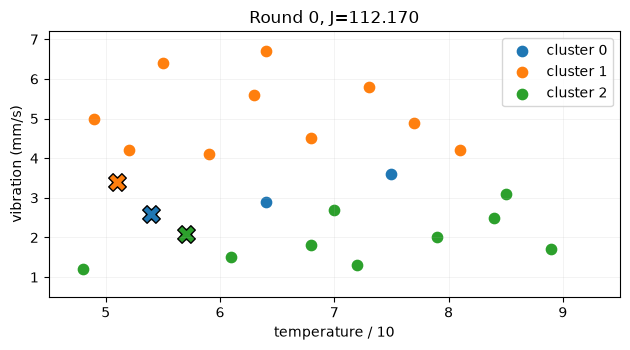

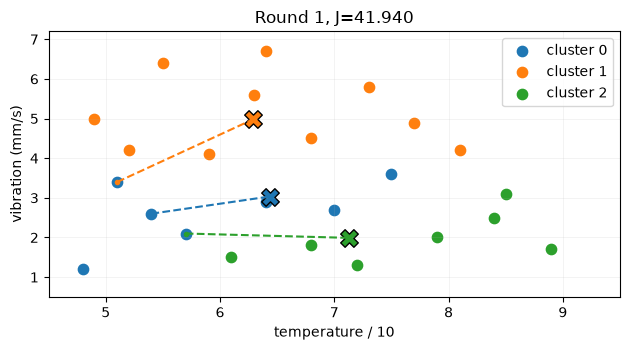

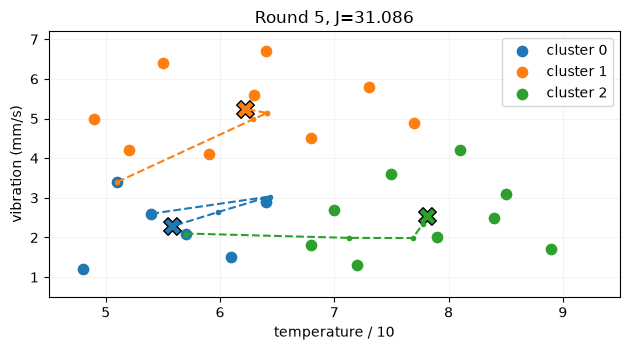

In [51]:
# X 是质心，虚线连接它在历轮中的位置。
for step in sorted({0, 1, len(centers_history) - 1}):
    plot_iteration(step)

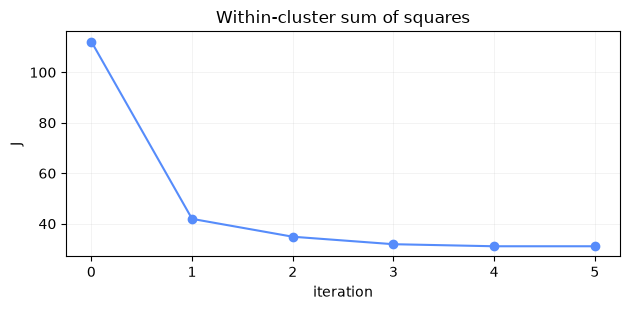

In [52]:
# 横轴是迭代次数，纵轴是簇内平方和 J。
# 第 0 轮对应初始质心，曲线显示损失逐步下降直到稳定。
plot_loss()